In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tidegravity import solve_longman_tide
from datetime import datetime
import matplotlib.dates as mdates

from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile
import boule as bl

from scipy.interpolate import interp1d
from pyproj import Proj
myProj_ant = Proj("+proj=stere +lat_0=-90 +lat_ts=-71")

C:\Users\maree\anaconda3\envs\denman\Lib\site-packages\boule\_triaxialellipsoid.py:15: UserWarning: A NumPy version >=1.25.2 and <2.6.0 is required for this version of SciPy (detected version 1.25.0)
  import scipy.special


1) Download the data 


Lösing, M., & Aitken, A. (2026). Denman Terrestrial Campaign – Ground-based gravity transect [Data set]. 
    
Institute for Marine and Antarctic Studies. https://doi.org/10.25959/RM9S-KT42

In [2]:
base_url = ("https://data.imas.utas.edu.au/attachments/" "5ba37235-2e9c-4850-91d8-1837b2d95778/")

archives = {"Bunger_Hills_Control_Xp4j0nR.zip": "Bunger_Hills_Control",
            "Casey_Base_Station_0cuVOWU.zip": "Casey_Base_Station",
            "Transect.zip": "Transect"}

data_dir = Path("data")
data_dir.mkdir(parents=True, exist_ok=True)

for filename, folder in archives.items():
    zip_path = data_dir / filename
    extract_dir = data_dir / folder
    marker = extract_dir / ".extraction_complete"

    # Skip downloading and extracting an already completed dataset.
    if marker.is_file():
        print(f"Already available: {folder}")
        continue

    # Reuse the ZIP if it has already been downloaded.
    if not zip_path.is_file():
        print(f"Downloading {filename}...")
        temporary_path = zip_path.with_suffix(".zip.part")
        urlretrieve(base_url + filename, temporary_path)
        temporary_path.replace(zip_path)
    else:
        print(f"Using existing archive: {filename}")

    # Extract and mark completion only after successful extraction.
    print(f"Extracting {filename}...")
    extract_dir.mkdir(parents=True, exist_ok=True)

    with ZipFile(zip_path) as archive:
        archive.extractall(extract_dir)

    marker.touch()

print("All datasets are available in:", data_dir.resolve())

Already available: Bunger_Hills_Control
Already available: Casey_Base_Station
Already available: Transect
All datasets are available in: E:\OneDrive - Expansion\Data\Denman Glacier\Fieldwork_Bunger_Hills\Gravity\Github\data


2. Drift calculation

In [3]:
# Instrument drift calculated by repeated measurements at the Casey Station and at three locations at the Bunger Hills camp
# This results in an average of the four fitted slopes, rather than one regression through all measurements. 
# Fitting each location separately prevents differences in gravity between locations from affecting the drift estimate.

casey = pd.read_excel(next(data_dir.rglob("Casey_Station.xlsx")))
bh = pd.read_excel(next(data_dir.rglob("Bunger_control.xlsx")))

casey = casey.loc[casey["Station no"] >= 1001].copy()
casey["datetime"] = pd.to_datetime(casey["Date"] + " " + casey["Time"].astype(str),format="%d.%m.%y %H:%M:%S")
bh["datetime"] = pd.to_datetime(bh["Date"] + " " + bh["time"].astype(str),format="%d.%m.%y %H:%M:%S")

# Casey: preserve original row order and exclude the last three readings.
reference_time = casey["datetime"].min()
t = (casey["datetime"] - reference_time).dt.total_seconds().to_numpy()
x = t[:-3]
g = casey["g"].to_numpy(dtype=float)[:-3]

slopes = [np.polyfit(x, g, 1)[0]]

# Bunger Hills: a separate slope for each control location.
for location in ["BH Base", "BH Station1", "BH Station2"]:
    subset = bh.loc[bh["name of loc"] == location]
    tb = (subset["datetime"] - subset["datetime"].min()).dt.total_seconds().to_numpy()
    slopes.append(np.polyfit(tb, subset["g"].to_numpy(dtype=float), 1)[0])

m_mean = np.mean(slopes)  # mGal/s

# Two endpoints define the regression line.
xx = np.array([x.min(), x.max()])
R = np.column_stack((xx,g.mean() + m_mean * (xx - x.mean())))

print("Time origin:", reference_time)
print(f"Mean drift: {m_mean * 86400:.6f} mGal/day")

Time origin: 2023-12-08 16:26:52
Mean drift: -0.006162 mGal/day


Absolute reference gravity at the Casey Station gravity reference site (mGal)

In [4]:
abs_ref = 982380.48867

 3. Read in raw gravity data

In [5]:
names = ['LINE', 'STATION', 'ALT.', 'GRAV.', 'SD.', 'TILTX', 'TILTY', 'TEMP', 'TIDE', 'DUR', 'REJ', 'TIME', 'DEC.TIME+DATE', 'TERRAIN', 'DATE']
Grav_loc = pd.read_csv(next(data_dir.rglob("T133526.TXT")), skiprows=34, names=names,sep=r"\s+")

site = [0,0,0,0,0,0,0,0,0,0,0,0,0,5,5, 4,4, 6,6, 9,9, 7,7, 2,2, 8,8, 1,1, 3,3, 5,5,0,0,0]
Grav_loc['Site'] = site

loc = pd.read_csv(next(data_dir.rglob("Coordinates_Height_Site.csv")))
Grav_loc = pd.merge(Grav_loc, loc, on='Site', how='left')
Grav_loc = Grav_loc[Grav_loc['Site']!=0]

Grav_loc['DATETIME'] = pd.to_datetime(Grav_loc['DATE'] + ' ' + Grav_loc['TIME'])
datetime_np_array = np.array([pd.Timestamp(x).to_pydatetime() for x in Grav_loc['DATETIME'].values])

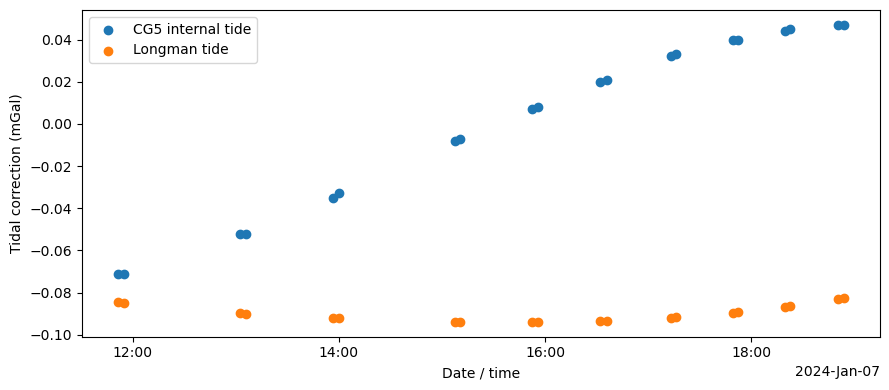

,LINE,STATION,ALT.,GRAV.,SD.,TILTX,TILTY,TEMP,TIDE,DUR,...,TIME,DEC.TIME+DATE,TERRAIN,DATE,Site,Lat,Lon,Height,DATETIME,TIDE_new
13,0.0,4005.0,12.7440,6051.800,0.028,-34.8,33.5,-3.48,-0.071,120,...,11:51:31,45266.49332,0.0,2024/01/07,5,-67.197612,99.462228,804.817,2024-01-07 11:51:31,-0.084491
14,0.0,4005.0,13.2323,6051.796,0.042,-9.9,5.9,-3.53,-0.071,120,...,11:54:38,45266.49548,0.0,2024/01/07,5,-67.197612,99.462228,804.817,2024-01-07 11:54:38,-0.084786


In [6]:
gm, gs, g0 = solve_longman_tide(np.array(Grav_loc.Lat), np.array(Grav_loc.Lon), np.array(Grav_loc.Height),datetime_np_array)

dates = pd.to_datetime(Grav_loc['DATETIME'],format='%Y-%m-%d %H:%M:%S')

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(dates, Grav_loc['TIDE'], label='CG5 internal tide')
ax.scatter(dates, g0, label='Longman tide')
locator = mdates.AutoDateLocator(minticks=3, maxticks=6)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.set_xlabel('Date / time')
ax.set_ylabel('Tidal correction (mGal)')
ax.legend()
fig.tight_layout()
plt.show()

Grav_loc['TIDE_new'] = g0
Grav_loc.head(2)

In [7]:
# Evaluate the drift at the time of each gravity measurement
x_new = (pd.to_datetime(Grav_loc["DATETIME"]) - reference_time).dt.total_seconds().to_numpy()

f = interp1d(R[:, 0], R[:, 1], kind="linear")
predicted_casey_reading = f(x_new)

In [8]:
Lat = Grav_loc.Lat
Heights = Grav_loc.Height # Ellipsoidal height (m), required by Boule

# Tie relative instrument readings to the Casey absolute gravity reference.
# predicted_casey_reading is the predicted Casey instrument reading at each measurement time,
# including the fitted instrument drift. 
Grav_loc["g_total"] = (Grav_loc["GRAV."] + abs_ref - predicted_casey_reading)
# Calculate WGS84 normal gravity at each measurement's latitude and height.
# Height dependence is included; no additional free-air correction is needed.
Grav_loc['g_n'] = bl.WGS84.normal_gravity(Lat, Heights)
# Subtract normal gravity and replace the CG-5 internal tide correction
# with the newly calculated correction.
# This quantity is a gravity disturbance, not the conventional Free Air anomaly.
Grav_loc['g_disturbance'] = Grav_loc['g_total'] - Grav_loc['g_n'] - Grav_loc['TIDE'] + Grav_loc['TIDE_new']

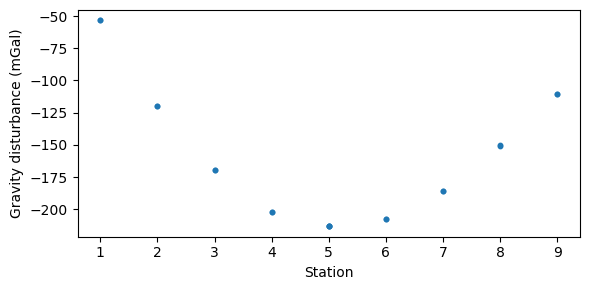

In [9]:
plt.figure(figsize=(6,3))
plt.scatter(Grav_loc.Site,Grav_loc['g_disturbance'],s=10)
plt.xlabel("Station")
plt.ylabel("Gravity disturbance (mGal)")
plt.tight_layout()
plt.show()

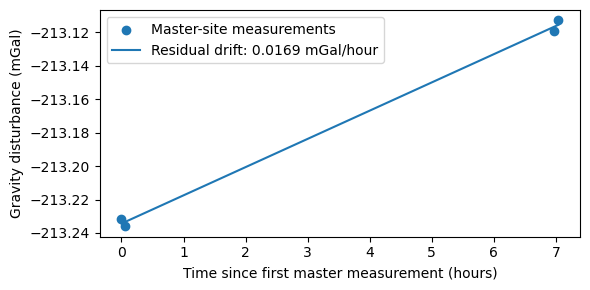

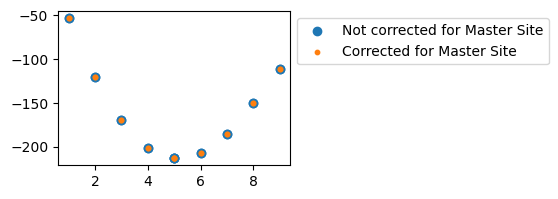

In [10]:
# Select repeated measurements at Site 5, the master/reference site during the transect operation.
# These observations are used to estimate the remaining time-dependent
# variation after the earlier Casey/Bunger instrument-drift correction.
Master = Grav_loc.loc[Grav_loc["Site"] == 5].copy()
Master["datetime"] = pd.to_datetime(Master["DATETIME"])
Master = Master.sort_values("datetime")

# Use the first master-site observation as the reference epoch (t = 0).
# The residual correction will be zero at this time.
master_reference_time = Master["datetime"].iloc[0]
t_master = (Master["datetime"] - master_reference_time).dt.total_seconds().to_numpy() / 3600
t_all = (pd.to_datetime(Grav_loc["DATETIME"]) - master_reference_time).dt.total_seconds().to_numpy() / 3600

# Fit the residual trend at the master site.
m_master, b_master = np.polyfit(t_master, Master["g_disturbance"].to_numpy(), 1)

# Remove only the time-dependent drift, preserving the fitted value at t=0.
Grav_loc["g_disturbance_Master_corr"] = (Grav_loc["g_disturbance"] - m_master * t_all)

fig, ax = plt.subplots(figsize=(6, 3))
ax.scatter(t_master, Master["g_disturbance"], label="Master-site measurements")
ax.plot(t_master,m_master * t_master + b_master,label=f"Residual drift: {m_master:.4f} mGal/hour",)
ax.set_xlabel("Time since first master measurement (hours)")
ax.set_ylabel("Gravity disturbance (mGal)")
ax.legend()
fig.tight_layout()
plt.show()

plt.figure(figsize=(3,2))
plt.scatter(Grav_loc.Site,Grav_loc['g_disturbance'], label='Not corrected for Master Site')
plt.scatter(Grav_loc.Site, Grav_loc['g_disturbance_Master_corr'],s=10, label='Corrected for Master Site')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
fig.tight_layout()
plt.show()

In [11]:
Grav_loc = Grav_loc.sort_values(by='Site')
# Keep one measurement per sitewha
Grav_loc_uni = Grav_loc[~Grav_loc['Site'].duplicated(keep='first')]

x, y = myProj_ant(Grav_loc_uni.Lon, Grav_loc_uni.Lat, inverse=False)

M = pd.DataFrame({
    "Easting_m": x,
    "Northing_m": y,
    "Longitude": Grav_loc_uni["Lon"].to_numpy(),
    "Latitude": Grav_loc_uni["Lat"].to_numpy(),
    "Gravity_disturbance_mGal": Grav_loc_uni["g_disturbance_Master_corr"].to_numpy(),
    "Ellipsoidal_height_m": Grav_loc_uni["Height"].to_numpy()})

M.to_csv("Gravity_Transect.csv", index=False)